In [4]:
!pip install duckdb

In [5]:
import duckdb

In [6]:
con = duckdb.connect()

In [7]:
result = con.execute("""
SELECT * FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
LIMIT 5
""").df()

result

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,52685,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55:00,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,55687,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55:00,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,10116,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:30:00,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,51382,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20:00,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,56164,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50:00,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [8]:
result = con.execute("""
SELECT COUNT(*) AS total_rows
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
""").df()

result

,total_rows
0,45584


In [9]:
result = con.execute("""
DESCRIBE
SELECT * FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
""").df()

result

,column_name,column_type,null,key,default,extra
0,ID,BIGINT,YES,None,None,None
1,Delivery_person_ID,VARCHAR,YES,None,None,None
2,Delivery_person_Age,DOUBLE,YES,None,None,None
3,Delivery_person_Ratings,DOUBLE,YES,None,None,None
4,Restaurant_latitude,DOUBLE,YES,None,None,None
5,Restaurant_longitude,DOUBLE,YES,None,None,None
6,Delivery_location_latitude,DOUBLE,YES,None,None,None
7,Delivery_location_longitude,DOUBLE,YES,None,None,None
8,Order_Date,DATE,YES,None,None,None
9,Time_Orderd,TIME,YES,None,None,None


In [10]:
result = con.execute("""
SELECT
  COUNT(*) AS total_rows,
  COUNT(Delivery_person_Age) AS non_missing_age,
  COUNT(*) - COUNT(Delivery_person_Age) AS missing_age
  FROM READ_CSV_AUTO('/content/zomato_cleaned_by_manisha.csv')
""").df()

result

,total_rows,non_missing_age,missing_age
0,45584,45584,0


In [11]:
result = con.execute("""
SELECT
COUNT(*) - COUNT(Delivery_person_Age) AS missing_age,
COUNT(*) - COUNT(Delivery_person_Ratings) AS missing_ratings,
COUNT(*) - COUNT(Restaurant_latitude) AS missing_restaurant_latitude,
COUNT(*) - COUNT(Restaurant_longitude) AS missing_restaurant_longitude
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
""").df()

result

,missing_age,missing_ratings,missing_restaurant_latitude,missing_restaurant_longitude
0,0,0,0,0


In [12]:
result = con.execute("""
SELECT
Weather_conditions,
COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Weather_conditions
ORDER BY total_orders DESC
""").df()

result

,Weather_conditions,total_orders
0,Fog,7653
1,Stormy,7584
2,Cloudy,7533
3,Sandstorms,7494
4,Windy,7422
5,Sunny,7282
6,Unknown,616


In [13]:
result = con.execute("""
SELECT
Road_traffic_density,
COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Road_traffic_density
ORDER BY total_orders DESC
""").df()

result

,Road_traffic_density,total_orders
0,Low,15476
1,Jam,14139
2,Medium,10945
3,High,4423
4,Unknown,601


In [14]:
result = con.execute("""
DESCRIBE
SELECT *
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
""").df()

result[['column_name', 'column_type']]

,column_name,column_type
0,ID,BIGINT
1,Delivery_person_ID,VARCHAR
2,Delivery_person_Age,DOUBLE
3,Delivery_person_Ratings,DOUBLE
4,Restaurant_latitude,DOUBLE
5,Restaurant_longitude,DOUBLE
6,Delivery_location_latitude,DOUBLE
7,Delivery_location_longitude,DOUBLE
8,Order_Date,DATE
9,Time_Orderd,TIME


In [15]:
result = con.execute("""
SELECT
    Road_traffic_density,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Road_traffic_density
ORDER BY total_orders DESC
""").df()

result

,Road_traffic_density,total_orders,avg_delivery_time
0,Low,15476,21.27
1,Jam,14139,31.18
2,Medium,10945,26.70
3,High,4423,27.24
4,Unknown,601,26.54


In [16]:
result = con.execute("""
SELECT
    Weather_conditions,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2)AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Weather_conditions
ORDER BY avg_delivery_time DESC
""").df()

result

,Weather_conditions,total_orders,avg_delivery_time
0,Cloudy,7533,28.92
1,Fog,7653,28.91
2,Unknown,616,26.55
3,Windy,7422,26.12
4,Sandstorms,7494,25.88
5,Stormy,7584,25.87
6,Sunny,7282,21.86


In [17]:
result = con.execute("""
SELECT
    Vehicle_condition,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY vehicle_condition
ORDER BY avg_delivery_time DESC
""").df()

result

,Vehicle_condition,total_orders,avg_delivery_time
0,0,15005,30.07
1,3,520,26.49
2,2,15031,24.45
3,1,15028,24.35


In [18]:
result = con.execute("""
SELECT
    multiple_deliveries,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY multiple_deliveries
ORDER BY avg_delivery_time DESC
""").df()

result

,multiple_deliveries,total_orders,avg_delivery_time
0,3.0,361,47.82
1,2.0,1985,40.45
2,1.0,28151,26.85
3,0.0,14094,22.88
4,Unknown,993,22.77


In [19]:
result = con.execute("""
SELECT
    Type_of_order,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Type_of_order
ORDER BY avg_delivery_time DESC
""").df()

result

,Type_of_order,total_orders,avg_delivery_time
0,Meal,11456,26.42
1,Snack,11530,26.29
2,Buffet,11277,26.28
3,Drinks,11321,26.19


In [20]:
result = con.execute("""
SELECT
    City,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY City
ORDER BY total_orders DESC
""").df()

result

,City,total_orders,avg_delivery_time
0,Metropolitian,34087,27.31
1,Urban,10133,22.98
2,Unknown,1200,22.06
3,Semi-Urban,164,49.73


In [21]:
result = con.execute("""
SELECT
    STRFTIME(Order_Date, '%y-%m') AS order_month,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY order_month
ORDER BY order_month
""").df()

result

,order_month,total_orders,avg_delivery_time
0,22-02,7242,26.53
1,22-03,31981,26.28
2,22-04,6361,26.12


In [22]:
result = con.execute("""
SELECT
    Road_traffic_density,
    Weather_Conditions,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY
    Road_traffic_density,
    Weather_Conditions
ORDER BY avg_delivery_time DESC
""").df()

result

,Road_traffic_density,Weather_conditions,total_orders,avg_delivery_time
0,High,Unknown,1,49.00
1,Jam,Fog,2428,36.81
2,Jam,Cloudy,2348,36.69
3,Jam,Unknown,3,35.33
4,Jam,Windy,2351,30.22
5,Jam,Sandstorms,2399,30.02
6,Jam,Stormy,2321,29.85
7,High,Cloudy,743,28.94
8,Medium,Cloudy,1837,28.48
9,High,Fog,776,28.43


In [23]:

result = con.execute("""
SELECT
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS average_delivery_time,
    MEDIAN("Time_taken (min)") AS median_delivery_time,
    MIN("Time_taken (min)") AS minimum_delivery_time,
    MAX("Time_taken (min)") AS maximum_delivery_time,
    ROUND(STDDEV("Time_taken (min)"), 2) AS delivery_time_std_dev
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
""").df()

result


,total_orders,average_delivery_time,median_delivery_time,minimum_delivery_time,maximum_delivery_time,delivery_time_std_dev
0,45584,26.29,26.0,10,54,9.38


In [24]:
import pandas as pd
import matplotlib.pyplot as plt


In [25]:
file_path = "/content/zomato_cleaned_by_manisha.csv"

df = pd.read_csv(file_path)

print("Dataset loaded for visualization. ")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded for visualization. 
Rows: 45584
Columns: 20


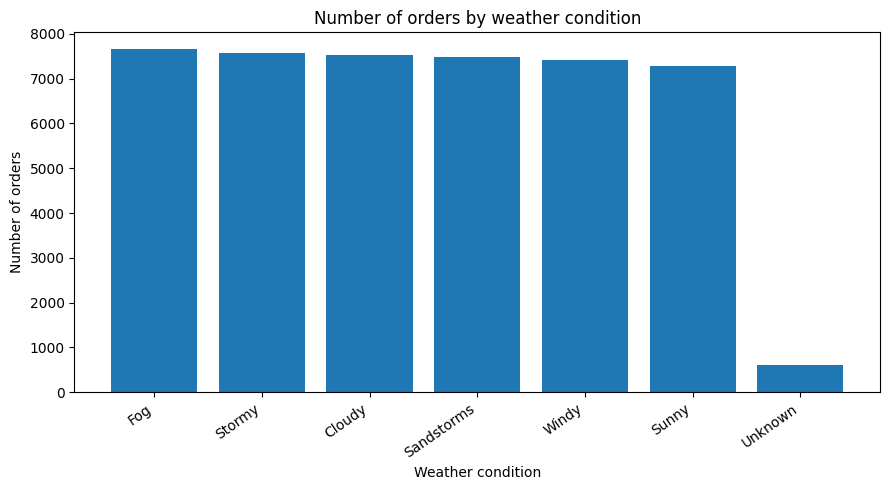

In [27]:
Weather_orders = con.execute("""
    SELECT
        Weather_conditions,
        COUNT(*) AS total_orders
    FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
    GROUP BY Weather_conditions
    ORDER BY total_orders DESC
""").df()

plt.figure(figsize=(9,5))

plt.bar(
    Weather_orders["Weather_conditions"].astype(str),
    Weather_orders["total_orders"]
)

plt.title("Number of orders by weather condition")
plt.xlabel("Weather condition")
plt.ylabel("Number of orders")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

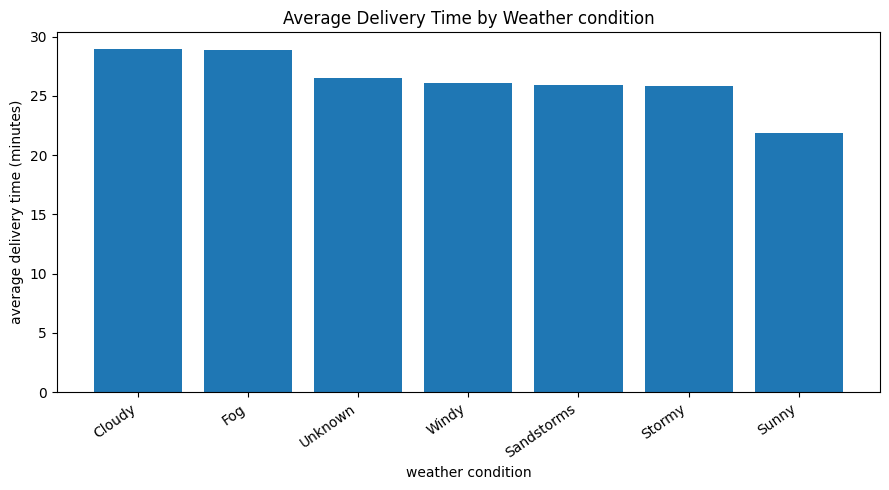

In [30]:
weather_time = con.execute("""
SELECT
    Weather_conditions,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Weather_conditions
ORDER BY avg_delivery_time DESC
""").df()

plt.figure(figsize = (9,5))

plt.bar(
    weather_time["Weather_conditions"].astype(str),
    weather_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Weather condition")
plt.xlabel("weather condition")
plt.ylabel("average delivery time (minutes)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

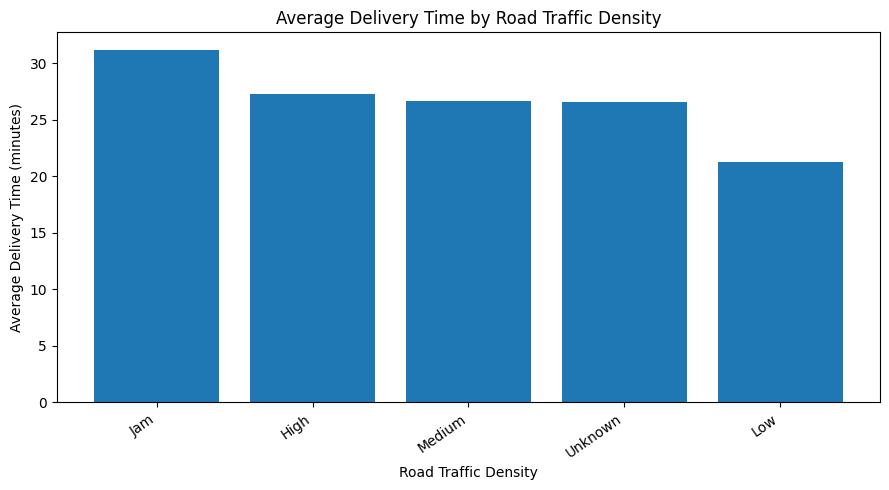

In [31]:

traffic_time = con.execute("""
SELECT
    Road_traffic_density,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Road_traffic_density
ORDER BY avg_delivery_time DESC
""").df()

plt.figure(figsize=(9, 5))

plt.bar(
    traffic_time["Road_traffic_density"].astype(str),
    traffic_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Road Traffic Density")
plt.xlabel("Road Traffic Density")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


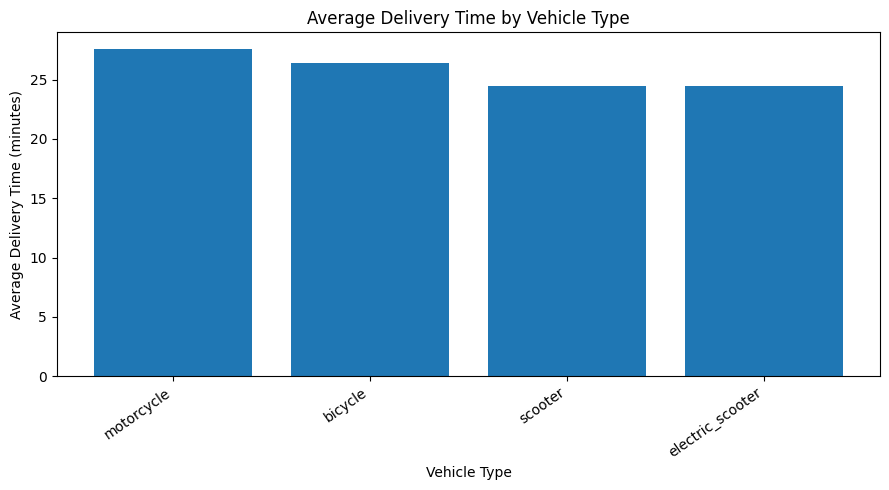

In [32]:

vehicle_time = con.execute("""
SELECT
    Type_of_vehicle,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Type_of_vehicle
ORDER BY avg_delivery_time DESC
""").df()

plt.figure(figsize=(9, 5))

plt.bar(
    vehicle_time["Type_of_vehicle"].astype(str),
    vehicle_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


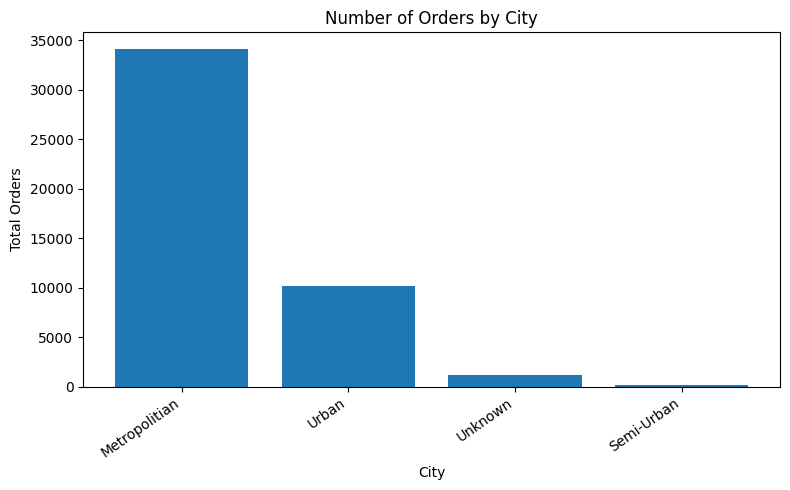

In [33]:

city_orders = con.execute("""
SELECT
    City,
    COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY City
ORDER BY total_orders DESC
""").df()

plt.figure(figsize=(8, 5))

plt.bar(
    city_orders["City"].astype(str),
    city_orders["total_orders"]
)

plt.title("Number of Orders by City")
plt.xlabel("City")
plt.ylabel("Total Orders")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


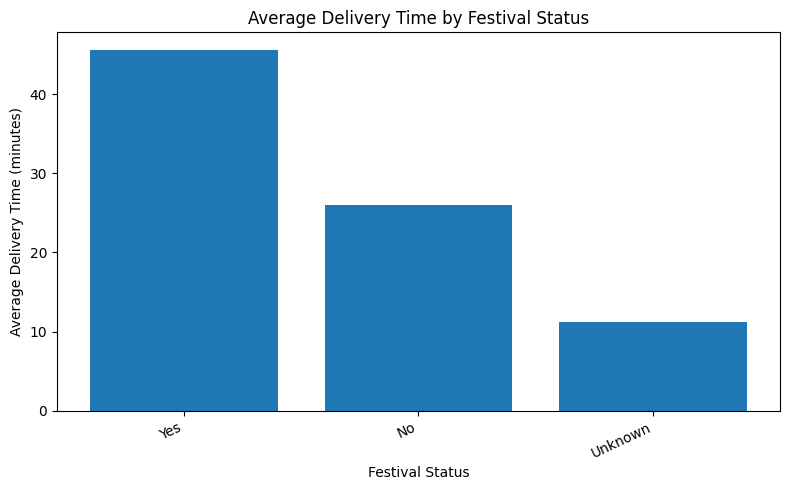

In [34]:

festival_time = con.execute("""
SELECT
    Festival,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Festival
ORDER BY avg_delivery_time DESC
""").df()

plt.figure(figsize=(8, 5))

plt.bar(
    festival_time["Festival"].astype(str),
    festival_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Festival Status")
plt.xlabel("Festival Status")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


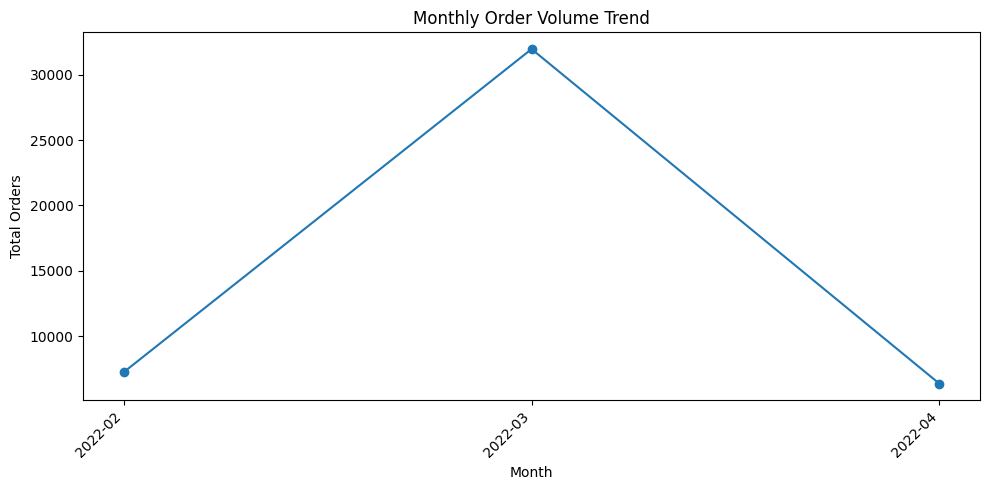

In [35]:

monthly_orders = con.execute("""
SELECT
    STRFTIME(Order_Date, '%Y-%m') AS order_month,
    COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY order_month
ORDER BY order_month
""").df()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_orders["order_month"].astype(str),
    monthly_orders["total_orders"],
    marker="o"
)

plt.title("Monthly Order Volume Trend")
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


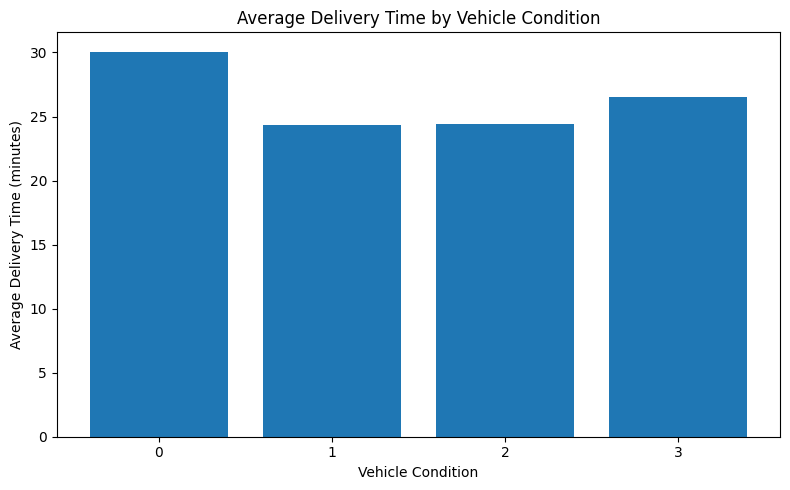

In [36]:

vehicle_condition_time = con.execute("""
SELECT
    Vehicle_condition,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Vehicle_condition
ORDER BY Vehicle_condition
""").df()

plt.figure(figsize=(8, 5))

plt.bar(
    vehicle_condition_time["Vehicle_condition"].astype(str),
    vehicle_condition_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Vehicle Condition")
plt.xlabel("Vehicle Condition")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()


In [37]:

# Save the SQL results needed for our EDA charts

weather_orders = con.execute("""
SELECT Weather_conditions, COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Weather_conditions
ORDER BY total_orders DESC
""").df()

weather_time = con.execute("""
SELECT Weather_conditions,
       ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Weather_conditions
ORDER BY avg_delivery_time DESC
""").df()

traffic_time = con.execute("""
SELECT Road_traffic_density,
       ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Road_traffic_density
ORDER BY avg_delivery_time DESC
""").df()

vehicle_time = con.execute("""
SELECT Type_of_vehicle,
       ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Type_of_vehicle
ORDER BY avg_delivery_time DESC
""").df()

city_orders = con.execute("""
SELECT City, COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY City
ORDER BY total_orders DESC
""").df()

festival_time = con.execute("""
SELECT Festival,
       COUNT(*) AS total_orders,
       ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Festival
ORDER BY avg_delivery_time DESC
""").df()

monthly_orders = con.execute("""
SELECT STRFTIME(Order_Date, '%Y-%m') AS order_month,
       COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY order_month
ORDER BY order_month
""").df()

vehicle_condition_time = con.execute("""
SELECT Vehicle_condition,
       COUNT(*) AS total_orders,
       ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY Vehicle_condition
ORDER BY Vehicle_condition
""").df()

print("All eight chart datasets are saved successfully.")


All eight chart datasets are saved successfully.


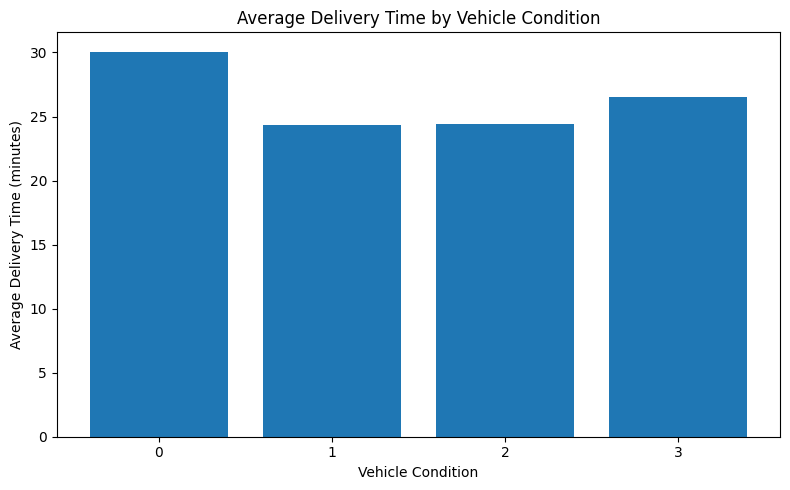

In [38]:
import matplotlib.pyplot as plt

vehicle_condition_time = con.execute("""
    SELECT
        Vehicle_condition,
        COUNT(*) AS total_orders,
        ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
    FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
    GROUP BY Vehicle_condition
    ORDER BY Vehicle_condition
""").df()

plt.figure(figsize=(8, 5))

plt.bar(
    vehicle_condition_time["Vehicle_condition"].astype(str),
    vehicle_condition_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Vehicle Condition")
plt.xlabel("Vehicle Condition")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

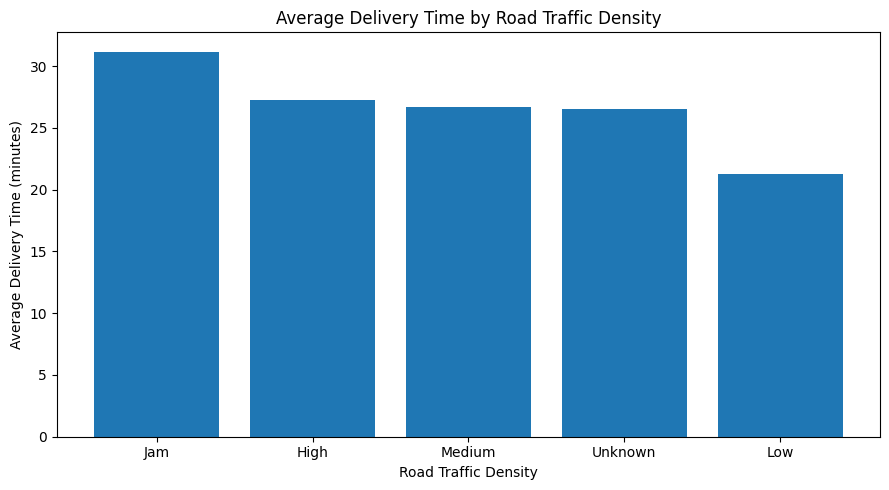

In [39]:
import matplotlib.pyplot as plt

traffic_time = con.execute("""
    SELECT
        Road_traffic_density,
        COUNT(*) AS total_orders,
        ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
    FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
    GROUP BY Road_traffic_density
    ORDER BY avg_delivery_time DESC
""").df()

plt.figure(figsize=(9, 5))

plt.bar(
    traffic_time["Road_traffic_density"].astype(str),
    traffic_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Road Traffic Density")
plt.xlabel("Road Traffic Density")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

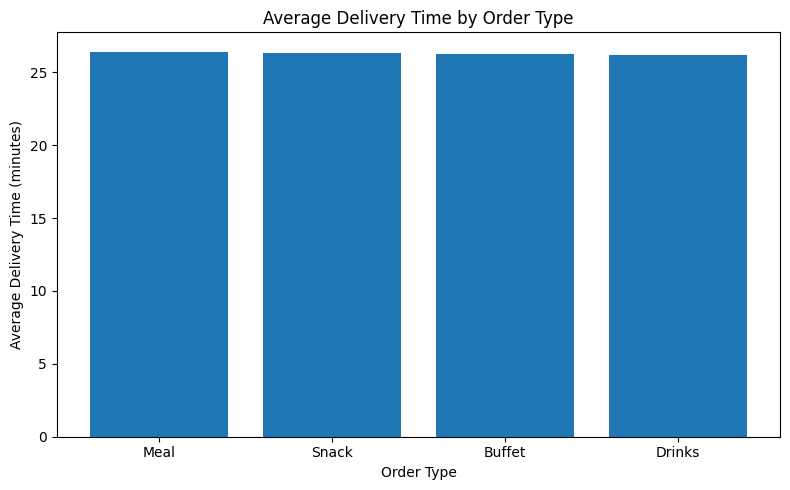

In [40]:
import matplotlib.pyplot as plt

order_type_time = con.execute("""
    SELECT
        Type_of_order,
        COUNT(*) AS total_orders,
        ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
    FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
    GROUP BY Type_of_order
    ORDER BY avg_delivery_time DESC
""").df()

plt.figure(figsize=(8, 5))

plt.bar(
    order_type_time["Type_of_order"].astype(str),
    order_type_time["avg_delivery_time"]
)

plt.title("Average Delivery Time by Order Type")
plt.xlabel("Order Type")
plt.ylabel("Average Delivery Time (minutes)")
plt.tight_layout()
plt.show()

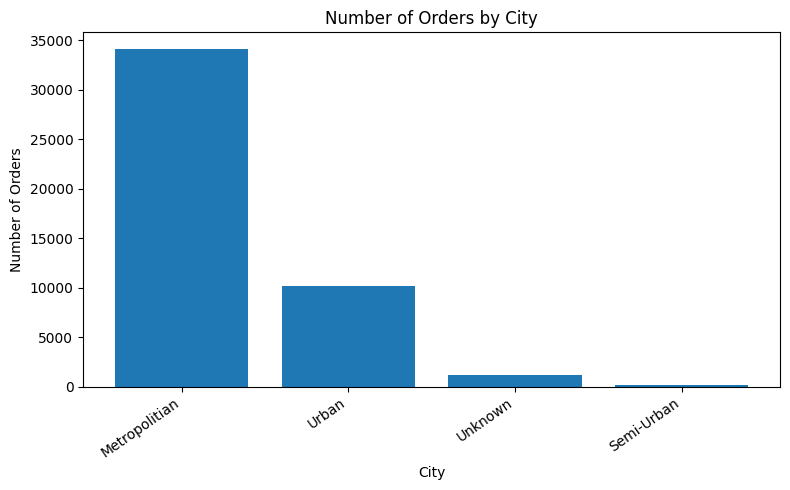

In [41]:
import matplotlib.pyplot as plt

city_orders = con.execute("""
    SELECT
        City,
        COUNT(*) AS total_orders
    FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
    GROUP BY City
    ORDER BY total_orders DESC
""").df()

plt.figure(figsize=(8, 5))

plt.bar(
    city_orders["City"].astype(str),
    city_orders["total_orders"]
)

plt.title("Number of Orders by City")
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [42]:

# Final analysis: Traffic and weather together

traffic_weather_summary = con.execute("""
SELECT
    Road_traffic_density,
    Weather_conditions,
    COUNT(*) AS total_orders,
    ROUND(AVG("Time_taken (min)"), 2) AS avg_delivery_time
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
GROUP BY
    Road_traffic_density,
    Weather_conditions
HAVING COUNT(*) >= 30
ORDER BY avg_delivery_time DESC
""").df()

display(traffic_weather_summary)


,Road_traffic_density,Weather_conditions,total_orders,avg_delivery_time
0,Jam,Fog,2428,36.81
1,Jam,Cloudy,2348,36.69
2,Jam,Windy,2351,30.22
3,Jam,Sandstorms,2399,30.02
4,Jam,Stormy,2321,29.85
5,High,Cloudy,743,28.94
6,Medium,Cloudy,1837,28.48
7,High,Fog,776,28.43
8,Medium,Fog,1852,28.04
9,Medium,Windy,1852,27.89


In [43]:

# Display the saved analysis results

print("1. Orders by Weather Condition")
display(weather_orders)

print("2. Average Delivery Time by Weather")
display(weather_time)

print("3. Average Delivery Time by Traffic Density")
display(traffic_time)

print("4. Average Delivery Time by Vehicle Type")
display(vehicle_time)

print("5. Orders by City")
display(city_orders)

print("6. Average Delivery Time by Festival Status")
display(festival_time)

print("7. Monthly Order Volume")
display(monthly_orders)

print("8. Average Delivery Time by Vehicle Condition")
display(vehicle_condition_time)

print("9. Traffic and Weather Combined")
display(traffic_weather_summary)


1. Orders by Weather Condition


,Weather_conditions,total_orders
0,Fog,7653
1,Stormy,7584
2,Cloudy,7533
3,Sandstorms,7494
4,Windy,7422
5,Sunny,7282
6,Unknown,616


2. Average Delivery Time by Weather


,Weather_conditions,avg_delivery_time
0,Cloudy,28.92
1,Fog,28.91
2,Unknown,26.55
3,Windy,26.12
4,Sandstorms,25.88
5,Stormy,25.87
6,Sunny,21.86


3. Average Delivery Time by Traffic Density


...

,order_month,total_orders
0,2022-02,7242
1,2022-03,31981
2,2022-04,6361


8. Average Delivery Time by Vehicle Condition


,Vehicle_condition,total_orders,avg_delivery_time
0,0,15005,30.07
1,1,15028,24.35
2,2,15031,24.45
3,3,520,26.49


9. Traffic and Weather Combined


,Road_traffic_density,Weather_conditions,total_orders,avg_delivery_time
0,Jam,Fog,2428,36.81
1,Jam,Cloudy,2348,36.69
2,Jam,Windy,2351,30.22
3,Jam,Sandstorms,2399,30.02
4,Jam,Stormy,2321,29.85
5,High,Cloudy,743,28.94
6,Medium,Cloudy,1837,28.48
7,High,Fog,776,28.43
8,Medium,Fog,1852,28.04
9,Medium,Windy,1852,27.89


In [44]:

# Check missing and unknown values in traffic and weather

missing_check = con.execute("""
SELECT
    Road_traffic_density,
    Weather_conditions,
    COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
WHERE Road_traffic_density IS NULL
   OR Weather_conditions IS NULL
   OR TRIM(CAST(Road_traffic_density AS VARCHAR)) = ''
   OR TRIM(CAST(Weather_conditions AS VARCHAR)) = ''
GROUP BY Road_traffic_density, Weather_conditions
ORDER BY total_orders DESC
""").df()

display(missing_check)


,Road_traffic_density,Weather_conditions,total_orders


In [45]:

unknown_check = con.execute("""
SELECT
    Road_traffic_density,
    Weather_conditions,
    COUNT(*) AS total_orders
FROM read_csv_auto('/content/zomato_cleaned_by_manisha.csv')
WHERE LOWER(TRIM(CAST(Road_traffic_density AS VARCHAR))) = 'unknown'
   OR LOWER(TRIM(CAST(Weather_conditions AS VARCHAR))) = 'unknown'
GROUP BY Road_traffic_density, Weather_conditions
ORDER BY total_orders DESC
""").df()

display(unknown_check)


,Road_traffic_density,Weather_conditions,total_orders
0,Unknown,Unknown,601
1,Low,Unknown,8
2,Jam,Unknown,3
3,Medium,Unknown,3
4,High,Unknown,1


In [46]:

print("WEATHER")
display(weather_time)

print("TRAFFIC")
display(traffic_time)

print("VEHICLE TYPE")
display(vehicle_time)

print("CITY")
display(city_orders)

print("FESTIVAL")
display(festival_time)

print("MONTHLY TREND")
display(monthly_orders)


WEATHER


,Weather_conditions,avg_delivery_time
0,Cloudy,28.92
1,Fog,28.91
2,Unknown,26.55
3,Windy,26.12
4,Sandstorms,25.88
5,Stormy,25.87
6,Sunny,21.86


TRAFFIC


,Road_traffic_density,total_orders,avg_delivery_time
0,Jam,14139,31.18
1,High,4423,27.24
2,Medium,10945,26.70
3,Unknown,601,26.54
4,Low,15476,21.27


VEHICLE TYPE


...

,City,total_orders
0,Metropolitian,34087
1,Urban,10133
2,Unknown,1200
3,Semi-Urban,164


FESTIVAL


,Festival,total_orders,avg_delivery_time
0,Yes,896,45.52
1,No,44460,25.98
2,Unknown,228,11.17


MONTHLY TREND


,order_month,total_orders
0,2022-02,7242
1,2022-03,31981
2,2022-04,6361


In [ ]:
# Business Insights and Recommendations — Zomato Delivery Dataset

 1. Impact of Traffic Density on Delivery Time

Finding: From my analysis, orders delivered during jam traffic took an average of 31.18 minutes, while orders during low traffic took 21.27 minutes.
 This is a difference of 9.91 minutes.

Business Recommendation: Zomato could consider traffic conditions while estimating delivery times and help delivery partners choose suitable routes to reduce delays.

 2. Impact of Weather Conditions on Delivery Time

Finding: Cloudy weather had the highest average delivery time at 28.92 minutes, closely followed by fog at 28.91 minutes. Sunny weather had the lowest
average delivery time at 21.86 minutes.

Business Recommendation: Weather conditions could be considered when estimating delivery times so customers receive more realistic delivery estimates during
unfavorable conditions.

 3. Relationship Between Vehicle Condition and Delivery Time

Finding: Vehicle condition category 0 had the highest average delivery time at 30.07 minutes. Categories 1 and 2 had average delivery times of 24.35 and
24.45 minutes, respectively.

Business Recommendation: The company could investigate the orders in vehicle condition category 0. Before drawing a conclusion, the meaning of each vehicle
condition category should be verified.

 4. Impact of Festivals on Delivery Time

Finding: Orders recorded during festivals took an average of 45.52 minutes, compared with 25.98 minutes for orders outside festivals.
The difference was 19.54 minutes.

Business Recommendation: Zomato could plan delivery-partner availability in advance during festivals and monitor delays to improve delivery performance.

 5. Distribution of Orders by City Category

Finding: Metropolitan areas recorded 34,087 orders, followed by urban areas with 10,133 orders. Metropolitan orders represented approximately 74.8% of all
 45,584 orders in the dataset.

Business Recommendation: Zomato could focus on improving delivery efficiency in metropolitan areas while collecting more data
before drawing conclusions about areas with fewer orders.

 Conclusion

Through this analysis, I found that traffic density, weather conditions, vehicle condition categories, festival periods,
and city categories show useful patterns in Zomato delivery data. These findings can help identify areas for further
investigation and improve delivery planning. Further analysis would be needed to confirm the causes of longer delivery times.

## Conclusion

In this project, I performed Exploratory Data Analysis (EDA) on the Zomato delivery dataset using SQL and data visualization. I analyzed delivery times across different weather conditions, traffic densities, vehicle types, vehicle condition categories, festival periods, city categories, and months.

The analysis helped identify patterns associated with longer delivery times and understand the distribution of orders across different categories. Based on these findings, I suggested practical recommendations to improve delivery planning and customer communication.

## Limitations

- Some records contain unknown values for weather, traffic density, city, and festival information.
- The meanings of the vehicle condition categories should be verified before drawing operational conclusions.
- The analysis identifies associations in the dataset and does not prove that a particular factor causes delivery delays.
- Monthly order counts may be affected by differences in data coverage across months.

## Tools Used

- SQL with DuckDB
- Python
- Pandas
- Data visualization in Google Colab
- GitHub for project version control and presentation